<a href="https://colab.research.google.com/github/VitorKF/Aulas-Programacao-para-Ciencia-de-Dados/blob/main/Usando_matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Utilizando o trecho de código abaixo, uma base fictícia de vendas, desenvolver um pequeno programa que utilize pandas, NumPy e Matplotlib para analisar dados e apresentar conclusões justificadas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)

print(df)

   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


In [2]:
# Primeiras linhas
print("Primeiras linhas:")
print(df.head())

# Dimensões do DataFrame
print("\nDimensões:")
print(df.shape)

# Estatísticas descritivas
print("\nEstatísticas descritivas:")
print(df.describe())

Primeiras linhas:
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

Dimensões:
(6, 4)

Estatísticas descritivas:
        Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000


In [3]:
produtos = ["Notebook", "Mouse", "Teclado"]

for produto in produtos:
    vendas = df[produto].to_numpy()

    print(f"\n{produto}:")
    print(f"Média: {np.mean(vendas):.2f}")
    print(f"Maior venda: {np.max(vendas)}")
    print(f"Menor venda: {np.min(vendas)}")


Notebook:
Média: 28.67
Maior venda: 40
Menor venda: 20

Mouse:
Média: 58.00
Maior venda: 70
Menor venda: 48

Teclado:
Média: 36.00
Maior venda: 45
Menor venda: 28


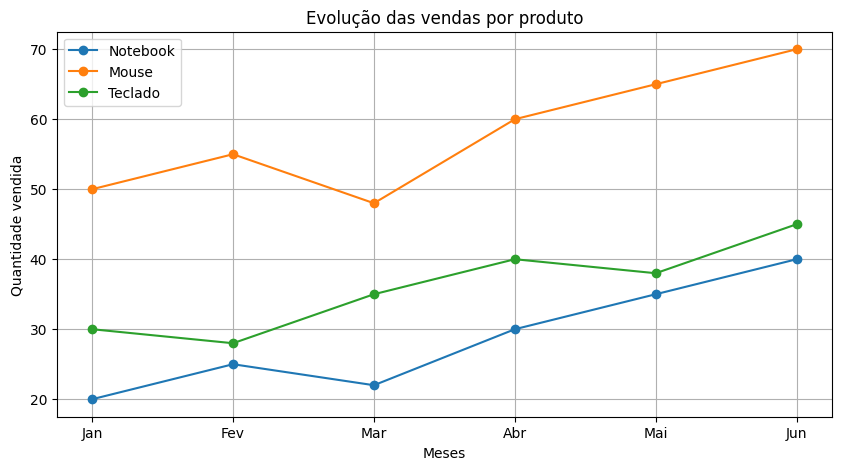

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(df["Mes"], df["Notebook"], marker="o", label="Notebook")
plt.plot(df["Mes"], df["Mouse"], marker="o", label="Mouse")
plt.plot(df["Mes"], df["Teclado"], marker="o", label="Teclado")

plt.title("Evolução das vendas por produto")
plt.xlabel("Meses")
plt.ylabel("Quantidade vendida")
plt.legend()
plt.grid(True)

plt.show()

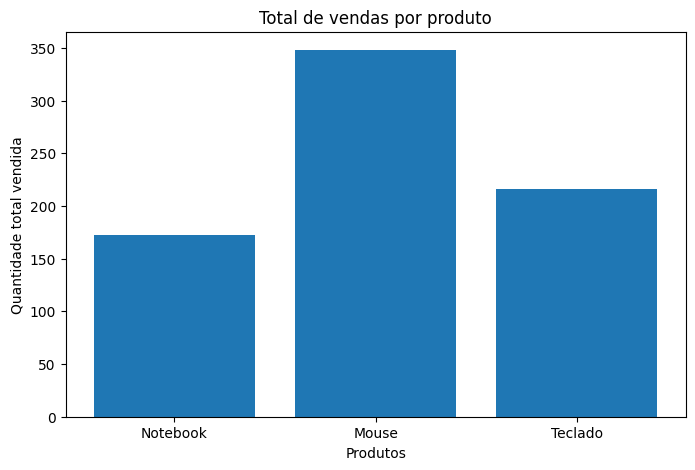

In [5]:
totais = df[produtos].sum()

plt.figure(figsize=(8, 5))

plt.bar(totais.index, totais.values)

plt.title("Total de vendas por produto")
plt.xlabel("Produtos")
plt.ylabel("Quantidade total vendida")

plt.show()

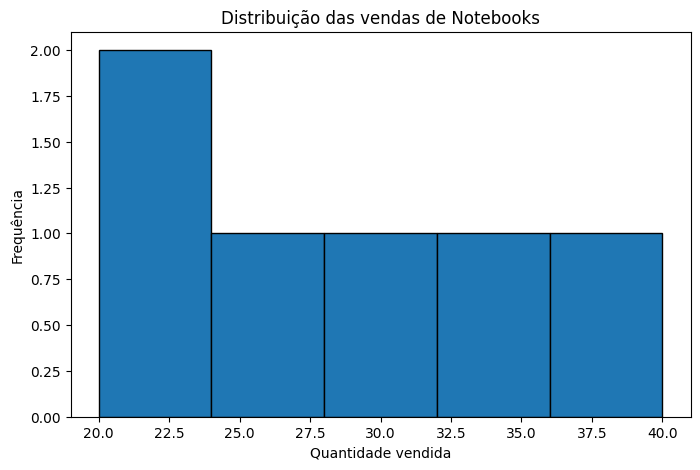

In [6]:
vendas_notebook = df["Notebook"].to_numpy()

plt.figure(figsize=(8, 5))

plt.hist(vendas_notebook, bins=5, edgecolor="black")

plt.title("Distribuição das vendas de Notebooks")
plt.xlabel("Quantidade vendida")
plt.ylabel("Frequência")

plt.show()

In [7]:
# Produto com maior volume total
totais = df[produtos].sum()

produto_maior_total = totais.idxmax()

print("Produto com maior volume total:")
print(f"{produto_maior_total}: {totais.max()} unidades")

# Mês de maior venda de cada produto
print("\nMês de maior venda por produto:")

for produto in produtos:
    indice = df[produto].idxmax()
    mes = df.loc[indice, "Mes"]
    quantidade = df.loc[indice, produto]

    print(f"{produto}: {mes} ({quantidade} unidades)")

Produto com maior volume total:
Mouse: 348 unidades

Mês de maior venda por produto:
Notebook: Jun (40 unidades)
Mouse: Jun (70 unidades)
Teclado: Jun (45 unidades)


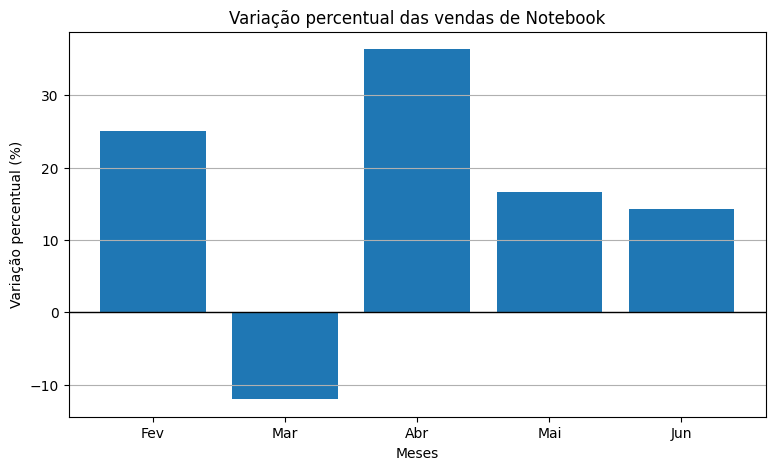

Variação percentual das vendas de Notebook:
Fev: 25.00%
Mar: -12.00%
Abr: 36.36%
Mai: 16.67%
Jun: 14.29%


In [8]:
# Valores de vendas de Notebook
vendas_notebook = df["Notebook"].to_numpy()

# Calculando a variação percentual entre os meses
variacao = np.diff(vendas_notebook) / vendas_notebook[:-1] * 100

# Meses correspondentes às variações
meses_variacao = df["Mes"].iloc[1:]

# Criando o gráfico
plt.figure(figsize=(9, 5))

plt.bar(meses_variacao, variacao)

plt.axhline(0, color="black", linewidth=1)

plt.title("Variação percentual das vendas de Notebook")
plt.xlabel("Meses")
plt.ylabel("Variação percentual (%)")

plt.grid(axis="y")

plt.show()

# Exibindo os valores
print("Variação percentual das vendas de Notebook:")

for mes, valor in zip(meses_variacao, variacao):
    print(f"{mes}: {valor:.2f}%")